<a href="https://colab.research.google.com/github/HelviaOliveira/dplyr/blob/main/Comportamento%20e%20Pagamentos.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Análise Clientes Olist

In [1]:
# manipuluação dos dados
import pandas as pd
import numpy as np

# visualização dos dados
import seaborn as sns
import matplotlib.pyplot as plt
import plotly.express as px

In [7]:
df_olist = pd.read_csv('olist_customers_dataset.csv')

In [11]:
df_olist.head()

,customer_id,customer_unique_id,customer_zip_code_prefix,customer_city,customer_state
0,06b8999e2fba1a1fbc88172c00ba8bc7,861eff4711a542e4b93843c6dd7febb0,14409,franca,SP
1,18955e83d337fd6b2def6b18a428ac77,290c77bc529b7ac935b93aa66c333dc3,9790,sao bernardo do campo,SP
2,4e7b3e00288586ebd08712fdd0374a03,060e732b5b29e8181a18229c7b0b2b5e,1151,sao paulo,SP
3,b2b6027bc5c5109e529d4dc6358b12c3,259dac757896d24d7702b9acbbff3f3c,8775,mogi das cruzes,SP
4,4f2d8ab171c80ec8364f7c12e35b23ad,345ecd01c38d18a9036ed96c73b8d066,13056,campinas,SP


In [13]:
import os
# Listando os arquivos no diretório atual para verificar quais bases da Olist estão disponíveis
files = os.listdir('/content')
print('Arquivos disponíveis em /content:', files)

Arquivos disponíveis em /content: ['.config', 'olist_customers_dataset.csv', 'sample_data']


In [14]:
import urllib.request
import zipfile
import os

# URL de um espelho público com os dados da Olist no GitHub
url = 'https://github.com/andresionek91/Olist-Dataset/raw/master/olist_datasets.zip'
zip_path = '/content/olist_datasets.zip'

print('Baixando os dados adicionais da Olist...')
try:
    urllib.request.urlretrieve(url, zip_path)
    with zipfile.ZipFile(zip_path, 'r') as zip_ref:
        zip_ref.extractall('/content')
    print('Download e extração concluídos!')
    # Listar os novos arquivos disponíveis
    print('Novos arquivos:', [f for f in os.listdir('/content') if f.endswith('.csv')])
except Exception as e:
    print('Erro ao baixar os dados:', e)
    print('Como alternativa, por favor faça o upload manual dos arquivos do Kaggle (olist_orders_dataset.csv, olist_order_payments_dataset.csv, olist_order_items_dataset.csv).')

Baixando os dados adicionais da Olist...
Erro ao baixar os dados: HTTP Error 404: Not Found
Como alternativa, por favor faça o upload manual dos arquivos do Kaggle (olist_orders_dataset.csv, olist_order_payments_dataset.csv, olist_order_items_dataset.csv).


In [19]:
import pandas as pd
import plotly.express as px
import plotly.graph_objects as go
from plotly.subplots import make_subplots

# Lendo o arquivo que possui delimitadores mistos (cabeçalho com vírgulas e dados com espaços)
try:
    # Usamos o mecanismo Regex engine para aceitar tanto vírgula quanto um ou mais espaços como separador
    df_payments = pd.read_csv('olist_order_payments_dataset.csv', sep=r',|\s+', engine='python')
except Exception as e:
    # Fallback caso ocorra algum imprevisto na leitura automática
    df_payments = pd.read_csv('olist_order_payments_dataset.csv', delim_whitespace=True)

# Limpando possíveis aspas e espaços extras nos nomes das colunas
df_payments.columns = df_payments.columns.str.replace('"', '').str.strip()

# 1. Meios de pagamento mais usados
payment_counts = df_payments['payment_type'].value_counts().reset_index()
payment_counts.columns = ['payment_type', 'count']

# Traduzindo os meios de pagamento para o português
traducao_pagamentos = {
    'credit_card': 'Cartão de Crédito',
    'boleto': 'Boleto',
    'voucher': 'Voucher',
    'debit_card': 'Cartão de Débito',
    'not_defined': 'Não Definido'
}
payment_counts['payment_type'] = payment_counts['payment_type'].map(traducao_pagamentos).fillna(payment_counts['payment_type'])

# 2. Valor médio das parcelas por número de parcelas (para cartão de crédito)
df_credit = df_payments[df_payments['payment_type'] == 'credit_card']
installments_value = df_credit.groupby('payment_installments')['payment_value'].mean().reset_index()

# Criando a figura com subplots
fig = make_subplots(
    rows=1, cols=2,
    subplot_titles=('Meios de Pagamento Mais Usados', 'Valor Médio das Parcelas por Nº de Parcelas (Cartão)'),
    specs=[[{'type': 'domain'}, {'type': 'xy'}]]
)

# Gráfico de Pizza para Meios de Pagamento
fig.add_trace(
    go.Pie(labels=payment_counts['payment_type'], values=payment_counts['count'], name="Meios de Pagamento", hole=.3),
    row=1, col=1
)

# Gráfico de Barras para Valor das Parcelas
fig.add_trace(
    go.Bar(x=installments_value['payment_installments'], y=installments_value['payment_value'], name="Valor Médio (R$)", marker_color='teal'),
    row=1, col=2
)

fig.update_layout(
    title_text="Análise de Meios de Pagamento e Parcelas (Olist)",
    template="plotly_white",
    height=500
)

fig.update_xaxes(title_text="Número de Parcelas", row=1, col=2)
fig.update_yaxes(title_text="Valor Médio (R$)", row=1, col=2)

fig.show()

In [20]:
import pandas as pd
import numpy as np

# Carregando as bases adicionais necessárias
df_orders = pd.read_csv('olist_orders_dataset.csv')
# Usamos o df_payments que já carregamos na célula anterior

# Ajustando tipos de dados de data
df_orders['order_purchase_timestamp'] = pd.to_datetime(df_orders['order_purchase_timestamp'])

# 1. Agrupando os pagamentos por pedido para ter o valor total de cada pedido
df_order_payments_total = df_payments.groupby('order_id')['payment_value'].sum().reset_index()

# 2. Mesclando as tabelas necessárias: Clientes (df_olist) + Pedidos (df_orders) + Pagamentos Totais
df_rfm_merged = df_orders.merge(df_olist, on='customer_id', how='inner')
df_rfm_merged = df_rfm_merged.merge(df_order_payments_total, on='order_id', how='inner')

# Definindo a data de referência para o cálculo de recência (dia seguinte à última compra no dataset)
data_referencia = df_rfm_merged['order_purchase_timestamp'].max() + pd.Timedelta(days=1)

# 3. Calculando Recência, Frequência e Monetização por customer_unique_id
df_rfm = df_rfm_merged.groupby('customer_unique_id').agg(
    Recencia=('order_purchase_timestamp', lambda x: (data_referencia - x.max()).days),
    Frequencia=('order_id', 'count'),
    Monetizacao=('payment_value', 'sum')
).reset_index()

# Visualizando as primeiras linhas do RFM estruturado
print("--- Prévia da Tabela RFM por customer_unique_id ---")
print(df_rfm.head())

# Estatísticas descritivas básicas do RFM
print("\n--- Estatísticas Descritivas do RFM ---")
print(df_rfm.describe())

--- Prévia da Tabela RFM por customer_unique_id ---
                 customer_unique_id  Recencia  Frequencia  Monetizacao
0  0000366f3b9a7992bf8c76cfdf3221e2       161           1       141.90
1  0000b849f77a49e4a4ce2b2a4ca5be3f       164           1        27.19
2  0000f46a3911fa3c0805444483337064       586           1        86.22
3  0000f6ccb0745a6a4b88665a16c9f078       370           1        43.62
4  0004aac84e0df4da2b147fca70cf8255       337           1       196.89

--- Estatísticas Descritivas do RFM ---
           Recencia    Frequencia   Monetizacao
count  96095.000000  96095.000000  96095.000000
mean     288.730756      1.034809    166.594226
std      153.407846      0.214385    231.428912
min        1.000000      1.000000      0.000000
25%      164.000000      1.000000     63.120000
50%      269.000000      1.000000    108.000000
75%      398.000000      1.000000    183.530000
max      773.000000     17.000000  13664.080000


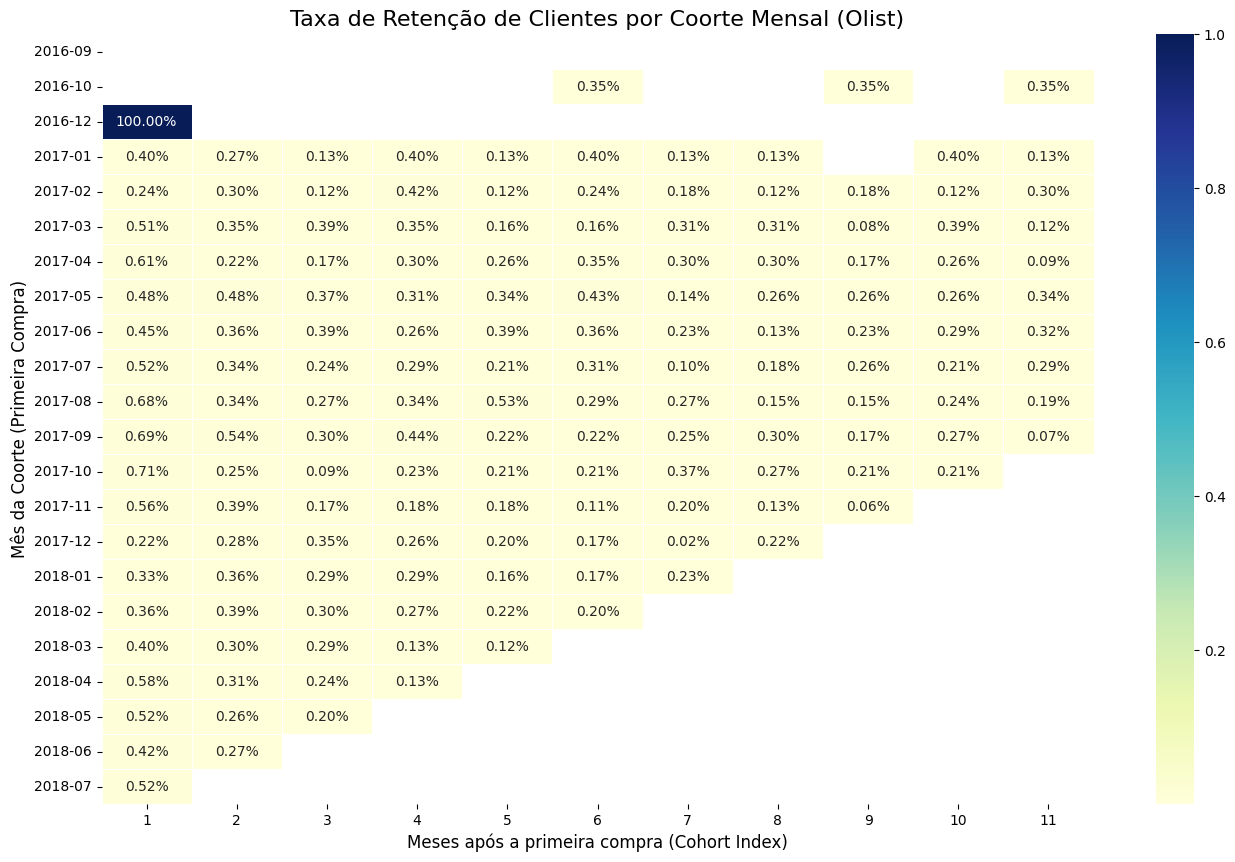

In [21]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

# 1. Unir df_orders com df_olist para ter o customer_unique_id associado às datas de compra
df_cohort = df_orders.merge(df_olist, on='customer_id', how='inner')

# Filtrar apenas pedidos entregues ou faturados para garantir compras válidas
df_cohort = df_cohort[df_cohort['order_status'].isin(['delivered', 'shipped', 'invoiced'])]

# Criar coluna do período de compra (Ano-Mês)
df_cohort['order_month'] = df_cohort['order_purchase_timestamp'].dt.to_period('M')

# 2. Identificar a coorte de cada cliente (mês da primeira compra)
df_cohort['cohort_month'] = df_cohort.groupby('customer_unique_id')['order_purchase_timestamp'].transform('min').dt.to_period('M')

# 3. Calcular a distância em meses entre a compra atual e a primeira compra (Coorte Index)
def calculate_cohort_index(df):
    years_diff = df['order_month'].dt.year - df['cohort_month'].dt.year
    months_diff = df['order_month'].dt.month - df['cohort_month'].dt.month
    return years_diff * 12 + months_diff

df_cohort['cohort_index'] = calculate_cohort_index(df_cohort)

# 4. Contar clientes únicos para cada coorte e index
cohort_group = df_cohort.groupby(['cohort_month', 'cohort_index'])['customer_unique_id'].nunique().reset_index()

# Pivotar os dados para criar a tabela de coorte
cohort_matrix = cohort_group.pivot(index='cohort_month', columns='cohort_index', values='customer_unique_id')

# 5. Calcular o percentual de retenção (dividindo cada mês pelo tamanho original da coorte no mês zero)
cohort_sizes = cohort_matrix.iloc[:, 0]
retention_matrix = cohort_matrix.divide(cohort_sizes, axis=0)

# 6. Plotar o Heatmap de Retenção por Coorte
plt.figure(figsize=(16, 10))
plt.title('Taxa de Retenção de Clientes por Coorte Mensal (Olist)', fontsize=16)
sns.heatmap(
    retention_matrix.iloc[:-1, 1:12], # Limitando visualmente aos primeiros 12 meses de retenção
    annot=True,
    fmt='.2%',
    cmap='YlGnBu',
    linewidths=.5
)
plt.xlabel('Meses após a primeira compra (Cohort Index)', fontsize=12)
plt.ylabel('Mês da Coorte (Primeira Compra)', fontsize=12)
plt.show()

In [22]:
import pandas as pd

# 1. Garantir que os nomes dos meios de pagamento estejam em português para melhor leitura
traducao_pagamentos = {
    'credit_card': 'Cartão de Crédito',
    'boleto': 'Boleto',
    'voucher': 'Voucher',
    'debit_card': 'Cartão de Débito',
    'not_defined': 'Não Definido'
}

df_payments['payment_type_pt'] = df_payments['payment_type'].map(traducao_pagamentos).fillna(df_payments['payment_type'])

# 2. Calcular estatísticas descritivas agrupadas pelo meio de pagamento
estatisticas_pagamento = df_payments.groupby('payment_type_pt')['payment_value'].agg([
    ('Qtd Transações', 'count'),
    ('Valor Total (R$)', 'sum'),
    ('Média (R$)', 'mean'),
    ('Desvio Padrão (R$)', 'std'),
    ('Mínimo (R$)', 'min'),
    ('Mediana (R$)', 'median'),
    ('Máximo (R$)', 'max')
]).reset_index()

# Formatar os valores numéricos para melhor visualização
pd.options.display.float_format = 'R$ {:,.2f}'.format
print("--- Estatísticas Descritivas Segmentadas por Meio de Pagamento ---")
display(estatisticas_pagamento)

--- Estatísticas Descritivas Segmentadas por Meio de Pagamento ---


,payment_type_pt,Qtd Transações,Valor Total (R$),Média (R$),Desvio Padrão (R$),Mínimo (R$),Mediana (R$),Máximo (R$)
0,Boleto,19784,"R$ 2,869,361.27",R$ 145.03,R$ 213.58,R$ 11.62,R$ 93.89,"R$ 7,274.88"
1,Cartão de Crédito,76795,"R$ 12,542,084.19",R$ 163.32,R$ 222.12,R$ 0.01,R$ 106.87,"R$ 13,664.08"
2,Cartão de Débito,1529,"R$ 217,989.79",R$ 142.57,R$ 245.79,R$ 13.38,R$ 89.30,"R$ 4,445.50"
3,Não Definido,3,R$ 0.00,R$ 0.00,R$ 0.00,R$ 0.00,R$ 0.00,R$ 0.00
4,Voucher,5775,"R$ 379,436.87",R$ 65.70,R$ 115.52,R$ 0.00,R$ 39.28,"R$ 3,184.34"


In [23]:
# Ordenar os clientes com base na coluna Monetizacao de forma decrescente
clientes_vip = df_rfm.sort_values(by='Monetizacao', ascending=False).head(10)

print("--- Top 10 Clientes com Maior Valor Gasto (Monetização) ---")
display(clientes_vip)

--- Top 10 Clientes com Maior Valor Gasto (Monetização) ---


,customer_unique_id,Recencia,Frequencia,Monetizacao
3826,0a0a92112bd4c708ca5fde585afaa872,384,1,"R$ 13,664.08"
26456,46450c74a0d8c5ca9395da1daac6c120,61,3,"R$ 9,553.02"
81961,da122df9eeddfedc1dc1f5349a1a690c,565,2,"R$ 7,571.63"
44447,763c8b1c9c68a0229c42c9fc6f662b93,95,1,"R$ 7,274.88"
82807,dc4802a71eae9be1dd28f5d788ceb526,612,1,"R$ 6,929.31"
26205,459bef486812aa25204be022145caa62,84,1,"R$ 6,922.21"
95805,ff4159b92c40ebe40454e3e6a7c35ed6,511,1,"R$ 6,726.66"
24121,4007669dec559734d6f53e029e360987,328,1,"R$ 6,081.54"
35070,5d0a2980b292d049061542014e8960bf,98,1,"R$ 4,809.44"
89687,eebb5dda148d3893cdaf5b5ca3040ccb,547,1,"R$ 4,764.34"


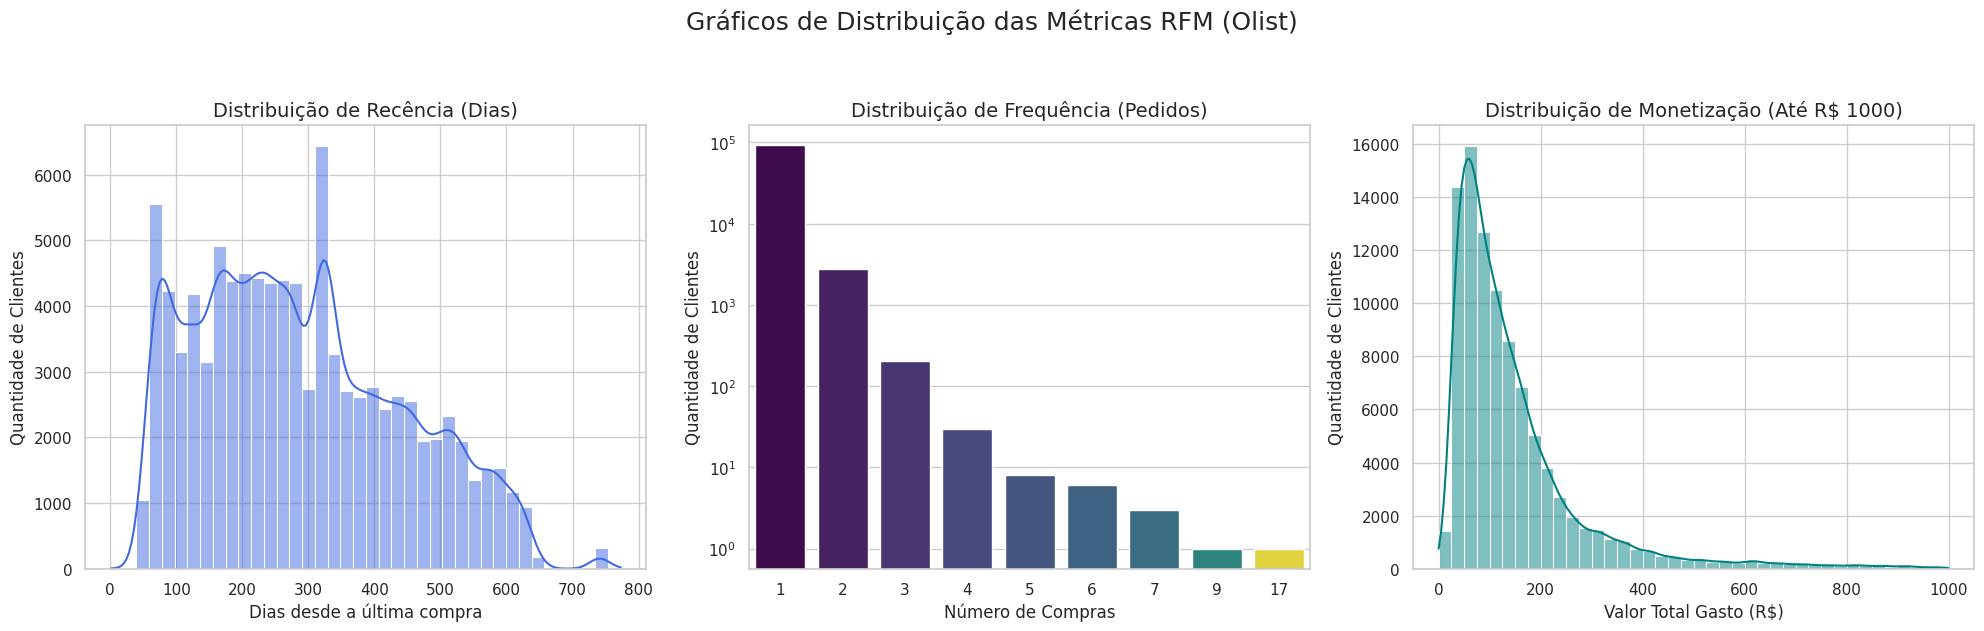

In [24]:
import matplotlib.pyplot as plt
import seaborn as sns

# Configurar o estilo visual dos gráficos
sns.set_theme(style="whitegrid")
fig, axes = plt.subplots(1, 3, figsize=(20, 6))

# 1. Distribuição de Recência
sns.histplot(df_rfm['Recencia'], bins=40, kde=True, ax=axes[0], color='royalblue')
axes[0].set_title('Distribuição de Recência (Dias)', fontsize=14)
axes[0].set_xlabel('Dias desde a última compra')
axes[0].set_ylabel('Quantidade de Clientes')

# 2. Distribuição de Frequência
# Como a grande maioria é frequência = 1, limitamos a visualização para melhor leitura
sns.countplot(data=df_rfm, x='Frequencia', ax=axes[1], palette='viridis', hue='Frequencia', legend=False)
axes[1].set_title('Distribuição de Frequência (Pedidos)', fontsize=14)
axes[1].set_xlabel('Número de Compras')
axes[1].set_ylabel('Quantidade de Clientes')
axes[1].set_yscale('log') # Escala logarítmica para evidenciar clientes recorrentes

# 3. Distribuição de Monetização
# Aplicamos um limite visual no eixo X (ex. até R$ 1000) para evitar distorções de outliers extremos no gráfico
monetizacao_filtrada = df_rfm[df_rfm['Monetizacao'] <= 1000]
sns.histplot(monetizacao_filtrada['Monetizacao'], bins=40, kde=True, ax=axes[2], color='teal')
axes[2].set_title('Distribuição de Monetização (Até R$ 1000)', fontsize=14)
axes[2].set_xlabel('Valor Total Gasto (R$)')
axes[2].set_ylabel('Quantidade de Clientes')

plt.suptitle('Gráficos de Distribuição das Métricas RFM (Olist)', fontsize=18, y=1.05)
plt.tight_layout()
plt.show()